# Rank / Expert Sweep: Partial Analysis

Compact inventory for the finished rank sweep and the partial expert/head sweep. The 11-run expert profile is only the current signal-checkpoint rerun subset; the full expert/head matrix is reconstructed from the output roots.

In [78]:
from pathlib import Path
import json, re
import pandas as pd

ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "configs/pipeline").exists() and (path / "outputs/pipeline_runs").exists()
)
RANK_PROFILE = "configs/pipeline/profiles/moe_study_rank_expert_sweep_noctua2_4gpu_alltargets_calibrated.generated.json"
SIGNAL_PROFILE = "configs/pipeline/profiles/moe_study_expert_head_sweep_r2_noctua2_4gpu_signal_3p6h.generated.json"
OUTPUT_ROOTS = {
    "rank": [
        "outputs/pipeline_runs/moe_study_rank_expert_sweep_noctua2_a100_4gpu_10_langs_alltargets_calibrated",
        "outputs/pipeline_runs/moe_study_rank_expert_sweep_noctua2_a100_4gpu_10_langs_rescue_kvdown",
        "outputs/pipeline_runs/moe_study_rank_expert_sweep_noctua2_a100_4gpu_10_langs_rescue_moelora_vonly",
        "outputs/pipeline_runs/moe_study_rank_expert_sweep_noctua2_a100_4gpu_failed_recovery_full",
    ],
    "expert_head": [
        "outputs/pipeline_runs/moe_study_expert_head_sweep_r2_noctua2_a100_4gpu_10_langs_working_calibrated",
        "outputs/pipeline_runs/moe_study_expert_head_sweep_r2_noctua2_a100_4gpu_10_langs_ready",
        "outputs/pipeline_runs/moe_study_expert_head_sweep_r2_noctua2_a100_4gpu_10_langs_final_rescue_nosync",
        "outputs/pipeline_runs/moe_study_expert_head_sweep_r2_noctua2_a100_4gpu_10_langs_deterministic_budget_filtered_save",
        "outputs/pipeline_runs/moe_study_expert_head_sweep_r2_noctua2_a100_4gpu_10_langs_signal_3p6h",
    ],
}

def load_profile(path):
    payload = json.loads((ROOT / path).read_text())
    return next(iter(payload.items()))

def observed_run_ids(label):
    ids = set()
    for root in OUTPUT_ROOTS[label]:
        run_root = ROOT / root / "runs"
        if run_root.exists():
            ids |= {path.name for path in run_root.iterdir() if path.is_dir()}
    return sorted(ids)

rank_name, rank_profile = load_profile(RANK_PROFILE)
signal_name, signal_profile = load_profile(SIGNAL_PROFILE)
inventory = pd.DataFrame([
    {"sweep": "rank", "source": rank_name, "runs": len(rank_profile["training"]["runs"]), "output_roots": len(OUTPUT_ROOTS["rank"])},
    {"sweep": "expert_head", "source": "observed output roots", "runs": len(observed_run_ids("expert_head")), "output_roots": len(OUTPUT_ROOTS["expert_head"])},
    {"sweep": "expert_head_signal_rerun", "source": signal_name, "runs": len(signal_profile["training"]["runs"]), "output_roots": 1},
])
inventory

,sweep,source,runs,output_roots
0,rank,moe_study_rank_expert_sweep_noctua2_a100_4gpu_...,55,4
1,expert_head,observed output roots,65,5
2,expert_head_signal_rerun,moe_study_expert_head_sweep_r2_noctua2_a100_4g...,11,1


In [79]:
TOTAL_RANK_RE = re.compile(r"_tr(\d+)_")
RANK_RE = re.compile(r"_r(\d+)(?:_|$)")
EXPERT_RE = re.compile(r"_e(\d+)(?:_|$)")
TOPK_RE = re.compile(r"_k(\d+)(?:_|$)")

def kind_from_id(run_id):
    if run_id.startswith("adamoe_1"):
        return "mola"
    if run_id.startswith("mov_"):
        return "movlora"
    return run_id.split("_", 1)[0]

def parse_run_id(label, run_id):
    rank = int(RANK_RE.search(run_id).group(1)) if RANK_RE.search(run_id) else None
    experts = int(EXPERT_RE.search(run_id).group(1)) if EXPERT_RE.search(run_id) else None
    total_rank = int(TOTAL_RANK_RE.search(run_id).group(1)) if TOTAL_RANK_RE.search(run_id) else rank
    return {
        "sweep": label,
        "run_id": run_id,
        "kind": kind_from_id(run_id),
        "rank_per_adapter": rank,
        "total_rank": total_rank,
        "experts": experts,
        "top_k": int(TOPK_RE.search(run_id).group(1)) if TOPK_RE.search(run_id) else None,
    }

rank_ids = [run["id"] for run in rank_profile["training"]["runs"]]
matrix = pd.DataFrame(
    [parse_run_id("rank", run_id) for run_id in rank_ids]
    + [parse_run_id("expert_head", run_id) for run_id in observed_run_ids("expert_head")]
)
matrix.head()

,sweep,run_id,kind,rank_per_adapter,total_rank,experts,top_k
0,rank,lora_r2,lora,2.0,2.0,NaN,NaN
1,rank,lora_r4,lora,4.0,4.0,NaN,NaN
2,rank,lora_r8,lora,8.0,8.0,NaN,NaN
3,rank,lora_r16,lora,16.0,16.0,NaN,NaN
4,rank,lora_r32,lora,32.0,32.0,NaN,NaN


In [80]:
matrix.groupby(["sweep", "kind", "experts", "top_k"], dropna=False).agg(
    runs=("run_id", "count"),
    ranks=("total_rank", lambda x: sorted({int(v) for v in x.dropna()})),
).reset_index()

,sweep,kind,experts,top_k,runs,ranks
0,expert_head,adamole,2.0,NaN,1,[2]
1,expert_head,adamole,4.0,NaN,1,[2]
2,expert_head,cola,NaN,NaN,5,[2]
3,expert_head,hmora,2.0,1.0,1,[2]
4,expert_head,hmora,4.0,1.0,1,[2]
...,...,...,...,...,...,...
56,rank,lora,NaN,NaN,10,"[2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]"
57,rank,moelora,8.0,2.0,6,"[16, 32, 64, 128, 256, 512]"
58,rank,mola,8.0,6.0,7,"[16, 32, 64, 128, 256, 512, 1024]"
59,rank,movlora,8.0,NaN,1,[]


In [81]:
settings_path = ROOT / "outputs/pipeline_runs/moe_study_rank_expert_sweep_noctua2_4gpu_batch_calibration_alltargets/calibrated_batch_settings.csv"
rank_exclusions = pd.read_csv(settings_path)
rank_exclusions = rank_exclusions[rank_exclusions["status"] != "included"]
rank_exclusions[["run_id", "kind", "anchor_id", "status", "num_processes", "target_global_batch"]]

,run_id,kind,anchor_id,status,num_processes,target_global_batch
18,cola_r512,cola,cola_r512,infeasible_bs1,4,48
19,cola_r1024,cola,cola_r1024,infeasible_bs1,4,48
28,hydralora_r512,hydralora,hydralora_r512,infeasible_bs1,4,48
29,hydralora_r1024,hydralora,hydralora_r1024,infeasible_bs1,4,48
36,moelora_tr1024_e8_k2,moelora,moelora_tr1024_e8_k2,infeasible_bs1,4,48
37,adamole_tr16_e8,adamole,NaN,infeasible_group_no_successful_anchor,4,48
38,adamole_tr32_e8,adamole,NaN,infeasible_group_no_successful_anchor,4,48
39,adamole_tr64_e8,adamole,NaN,infeasible_group_no_successful_anchor,4,48
40,adamole_tr128_e8,adamole,NaN,infeasible_group_no_successful_anchor,4,48
41,adamole_tr256_e8,adamole,NaN,infeasible_group_no_successful_anchor,4,48


In [82]:
rank_columns = ["2", "4", "8", "16", "32", "64", "128", "256", "512", "1024", "rankless"]
rank_settings = pd.read_csv(settings_path)
rank_kinds = sorted(rank_settings["kind"].unique())
rank_status_matrix = pd.DataFrame("not planned", index=rank_kinds, columns=rank_columns)

def benchmark_done(run_id):
    return any((ROOT / root / "benchmarks" / run_id).is_dir() for root in OUTPUT_ROOTS["rank"])

for row in rank_settings.itertuples(index=False):
    parsed = parse_run_id("rank", row.run_id)
    col = "rankless" if pd.isna(parsed["total_rank"]) else str(int(parsed["total_rank"]))
    if row.status == "included":
        value = "done" if benchmark_done(row.run_id) else "missing"
    elif row.status == "infeasible_bs1":
        value = "infeasible bs1"
    else:
        value = "infeasible group"
    rank_status_matrix.loc[row.kind, col] = value

def color_rank_status(value):
    colors = {
        "done": "background-color: #c6efce; color: #006100",
        "missing": "background-color: #ffeb9c; color: #9c6500",
        "infeasible bs1": "background-color: #f4cccc; color: #990000",
        "infeasible group": "background-color: #eadcf8; color: #5b2b82",
        "not planned": "background-color: #eeeeee; color: #666666",
    }
    return colors.get(value, "")

rank_status_matrix.style.map(color_rank_status)

,2,4,8,16,32,64,128,256,512,1024,rankless
adamole,not planned,not planned,not planned,infeasible group,infeasible group,infeasible group,infeasible group,infeasible group,infeasible group,infeasible group,not planned
cola,done,done,done,done,done,done,done,done,infeasible bs1,infeasible bs1,not planned
hmora,not planned,not planned,not planned,done,done,done,done,done,done,done,not planned
hydralora,done,done,done,done,done,done,done,done,infeasible bs1,infeasible bs1,not planned
lora,done,done,done,done,done,done,done,done,done,done,not planned
moelora,not planned,not planned,not planned,done,done,done,done,done,done,infeasible bs1,not planned
mola,not planned,not planned,not planned,done,done,done,done,done,done,done,not planned
movlora,not planned,not planned,not planned,not planned,not planned,not planned,not planned,not planned,not planned,not planned,done
mtllora,done,done,done,done,done,done,done,done,infeasible bs1,infeasible bs1,not planned


In [83]:
HEADS_RE = re.compile(r"_heads(\d+)$")
NUP_RE = re.compile(r"_nup(\d+)$")
AB_RE = re.compile(r"_a(\d+)_b(\d+)$")

# Shared count axis: experts for MoE methods, heads for HydraLoRA,
# num-up projections for MTL-LoRA, and CoLA's b value for CoLA.
expert_count_columns = ["2", "4", "8", "16", "32"]

def expert_count(run_id):
    if AB_RE.search(run_id):
        return int(AB_RE.search(run_id).group(2))
    if HEADS_RE.search(run_id):
        return int(HEADS_RE.search(run_id).group(1))
    if NUP_RE.search(run_id):
        return int(NUP_RE.search(run_id).group(1))
    if EXPERT_RE.search(run_id):
        return int(EXPERT_RE.search(run_id).group(1))
    return None

APPROACH_ORDER = ["moelora", "adamole", "mola", "movlora", "hmora", "hydralora", "mtllora", "cola"]
APPROACH_LABELS = {
    "moelora": "MoE-LoRA",
    "adamole": "AdaMoLE",
    "mola": "MoLA",
    "movlora": "MoV",
    "hmora": "HMoRA",
    "hydralora": "HydraLoRA",
    "mtllora": "MTL-LoRA",
    "cola": "CoLA",
}

def expert_row_key(run_id):
    kind = kind_from_id(run_id)
    if kind in {"hmora", "mola", "movlora", "moelora"}:
        top_k = TOPK_RE.search(run_id)
        variant = f"top-k {top_k.group(1)}" if top_k else "all"
    elif kind == "hydralora":
        variant = "heads"
    elif kind == "mtllora":
        variant = "num projections"
    elif kind == "cola":
        variant = "b value"
    else:
        variant = "all"
    return (APPROACH_LABELS.get(kind, kind), variant)

def expert_row_sort_key(row_key):
    approach, variant = row_key
    kind_order = {APPROACH_LABELS[kind]: i for i, kind in enumerate(APPROACH_ORDER)}
    nums = [int(value) for value in re.findall(r"\d+", variant)]
    return (kind_order.get(approach, 999), nums or [0], variant)

expert_ids = observed_run_ids("expert_head")
expert_rows = sorted({expert_row_key(run_id) for run_id in expert_ids}, key=expert_row_sort_key)
expert_status_matrix = pd.DataFrame(
    "not planned",
    index=pd.MultiIndex.from_tuples(expert_rows, names=["approach", "variant"]),
    columns=expert_count_columns,
)

def expert_benchmark_done(run_id):
    return any((ROOT / root / "benchmarks" / run_id).is_dir() for root in OUTPUT_ROOTS["expert_head"])

for run_id in expert_ids:
    count = expert_count(run_id)
    if count is not None:
        expert_status_matrix.loc[expert_row_key(run_id), str(count)] = "done" if expert_benchmark_done(run_id) else "missing"

expert_status_matrix.style.map(color_rank_status)

In [84]:
def completion_rows(label, run_ids):
    roots = [ROOT / path for path in OUTPUT_ROOTS[label]]
    rows = []
    for run_id in run_ids:
        run_dirs = [root / "runs" / run_id for root in roots]
        rows.append({
            "sweep": label,
            "run_id": run_id,
            "train_dir": any(path.is_dir() for path in run_dirs),
            "adapter_artifact": any((path / "adapter_config.json").exists() or any(path.glob("checkpoint-*_adapter/adapter_config.json")) for path in run_dirs),
            "final_eval": any((root / "final_eval_loss" / f"{run_id}.json").exists() for root in roots),
            "benchmark_dir": any((root / "benchmarks" / run_id).is_dir() for root in roots),
        })
    return pd.DataFrame(rows)

status = pd.concat([
    completion_rows("rank", rank_ids),
    completion_rows("expert_head", observed_run_ids("expert_head")),
], ignore_index=True)
status.groupby("sweep")[["train_dir", "adapter_artifact", "final_eval", "benchmark_dir"]].sum().astype(int)

,train_dir,adapter_artifact,final_eval,benchmark_dir
sweep,,,,
expert_head,65,65,0,65
rank,55,55,0,55


In [85]:
# Compact source table for follow-up plots/statistics.
analysis_table = matrix.merge(status, on=["sweep", "run_id"], how="left")
analysis_table.sort_values(["sweep", "kind", "experts", "top_k", "total_rank", "run_id"]).head(20)

,sweep,run_id,kind,rank_per_adapter,total_rank,experts,top_k,train_dir,adapter_artifact,final_eval,benchmark_dir
70,expert_head,adamole_r2_e2,adamole,2.0,2.0,2.0,NaN,True,True,False,True
71,expert_head,adamole_r2_e4,adamole,2.0,2.0,4.0,NaN,True,True,False,True
72,expert_head,cola_r2_a11_b16,cola,2.0,2.0,NaN,NaN,True,True,False,True
73,expert_head,cola_r2_a1_b2,cola,2.0,2.0,NaN,NaN,True,True,False,True
74,expert_head,cola_r2_a21_b32,cola,2.0,2.0,NaN,NaN,True,True,False,True
75,expert_head,cola_r2_a3_b4,cola,2.0,2.0,NaN,NaN,True,True,False,True
76,expert_head,cola_r2_a5_b8,cola,2.0,2.0,NaN,NaN,True,True,False,True
81,expert_head,hmora_r2_e2_k1,hmora,2.0,2.0,2.0,1.0,True,True,False,True
87,expert_head,hmora_r2_e4_k1,hmora,2.0,2.0,4.0,1.0,True,True,False,True
88,expert_head,hmora_r2_e4_k2,hmora,2.0,2.0,4.0,2.0,True,True,False,True


## Combined rank benchmark selection

This uses the same combined rank result roots as `scripts/analysis/rank_sweep_select_best_rank.py`, but keeps the compact pandas aggregation and plots in the notebook. Scores are min-max normalized per task metric, then macro-averaged across Belebele, FLORES, SIB200, and Taxi1500.


In [86]:
# Rank benchmark aggregation from combined result roots.
import sys
sys.path.insert(0, str(ROOT))

from scripts.analysis.rank_sweep_select_best_rank import (
    DEFAULT_PROFILE, DEFAULT_ROOTS, _collect_raw_rows, _load_profile, _normalized_scores
)

profile = _load_profile(ROOT / "configs/pipeline", DEFAULT_PROFILE)
roots = [ROOT / root for root in DEFAULT_ROOTS]
_, raw_rows = _collect_raw_rows(profile, roots)
rank_metrics = pd.DataFrame(_normalized_scores(raw_rows))

benchmarks = ["Belebele", "FLORES", "SIB200", "Taxi1500"]
run_scores = (
    rank_metrics
    .groupby(["run_id", "kind", "rank_label", "total_rank", "benchmark"], dropna=False)["normalized_score"]
    .mean().unstack("benchmark").reindex(columns=benchmarks)
    .assign(aggregate_score=lambda df: df[benchmarks].mean(axis=1))
    .reset_index().sort_values("aggregate_score", ascending=False)
)

# Exact benchmark values for readable per-family plots.
# FLORES is stored as bits-per-byte; convert to byte perplexity as 2**bits_per_byte.
exact_metric_rows = rank_metrics.assign(
    exact_value=lambda df: df.apply(
        lambda row: 2 ** row.value if row.benchmark == "FLORES" else row.value,
        axis=1,
    )
)
exact_scores = (
    exact_metric_rows
    .groupby(["run_id", "kind", "rank_label", "total_rank", "benchmark"], dropna=False)["exact_value"]
    .mean().unstack("benchmark").reindex(columns=benchmarks)
    .reset_index()
)

shared_moe = run_scores[run_scores.kind.isin(["moelora", "mola", "hmora"]) & run_scores.total_rank.notna()]
shared_ranks = shared_moe.groupby("total_rank").kind.nunique().loc[lambda s: s.eq(3)].index
moe_rank_summary = (
    shared_moe[shared_moe.total_rank.isin(shared_ranks)]
    .groupby("total_rank", as_index=False)
    .agg(runs=("run_id", "count"), score=("aggregate_score", "mean"), **{b: (b, "mean") for b in benchmarks})
    .sort_values("score", ascending=False)
)

exact_shared_moe = exact_scores[exact_scores.kind.isin(["moelora", "mola", "hmora"]) & exact_scores.total_rank.isin(shared_ranks)]
exact_moe_rank_summary = (
    exact_shared_moe
    .groupby("total_rank", as_index=False)
    .agg(runs=("run_id", "count"), **{b: (b, "mean") for b in benchmarks})
    .sort_values("total_rank")
)

display(run_scores.head(15))
display(moe_rank_summary)
display(exact_moe_rank_summary)



benchmark,run_id,kind,rank_label,total_rank,Belebele,FLORES,SIB200,Taxi1500,aggregate_score
34,moelora_tr16_e8_k2,moelora,tr16,16.0,0.924328,0.999628,0.952382,0.947654,0.955998
54,mtllora_r8,mtllora,r8,8.0,0.902194,0.999575,0.932289,0.912540,0.936649
10,hmora_tr16_e8_k2,hmora,tr16,16.0,0.875779,0.999023,0.947642,0.883314,0.926439
17,hydralora_r2,hydralora,r2,2.0,0.924806,0.999500,0.948885,0.779404,0.913149
40,mola_tr128_e8_k6,mola,tr128,128.0,0.927432,0.999201,0.931883,0.788546,0.911766
12,hmora_tr32_e8_k2,hmora,tr32,32.0,0.797695,0.997832,0.940329,0.892312,0.907042
41,mola_tr16_e8_k6,mola,tr16,16.0,0.945073,0.999742,0.923892,0.745064,0.903443
43,mola_tr32_e8_k6,mola,tr32,32.0,0.912948,0.999692,0.921531,0.776138,0.902577
36,moelora_tr32_e8_k2,moelora,tr32,32.0,0.918085,0.999457,0.920340,0.765769,0.900913
38,moelora_tr64_e8_k2,moelora,tr64,64.0,0.929471,0.999531,0.955922,0.714075,0.899750


,total_rank,runs,score,Belebele,FLORES,SIB200,Taxi1500
0,16.0,3,0.928627,0.915060,0.999464,0.941305,0.858677
1,32.0,3,0.903511,0.876243,0.998994,0.927400,0.811406
2,64.0,3,0.867260,0.887143,0.998428,0.900404,0.683067
3,128.0,3,0.844332,0.781849,0.996140,0.933033,0.666305
4,256.0,3,0.772642,0.685052,0.990293,0.825336,0.589886
5,512.0,3,0.700114,0.609874,0.959068,0.797488,0.434026


,total_rank,runs,Belebele,FLORES,SIB200,Taxi1500
0,16.0,3,0.553539,1.462429,0.725263,0.333222
1,32.0,3,0.544321,1.465714,0.714447,0.318347
2,64.0,3,0.545638,1.469801,0.694966,0.270640
3,128.0,3,0.508066,1.485663,0.720483,0.265933
4,256.0,3,0.471440,1.529974,0.638972,0.241269
5,512.0,3,0.442757,1.805060,0.619674,0.186331


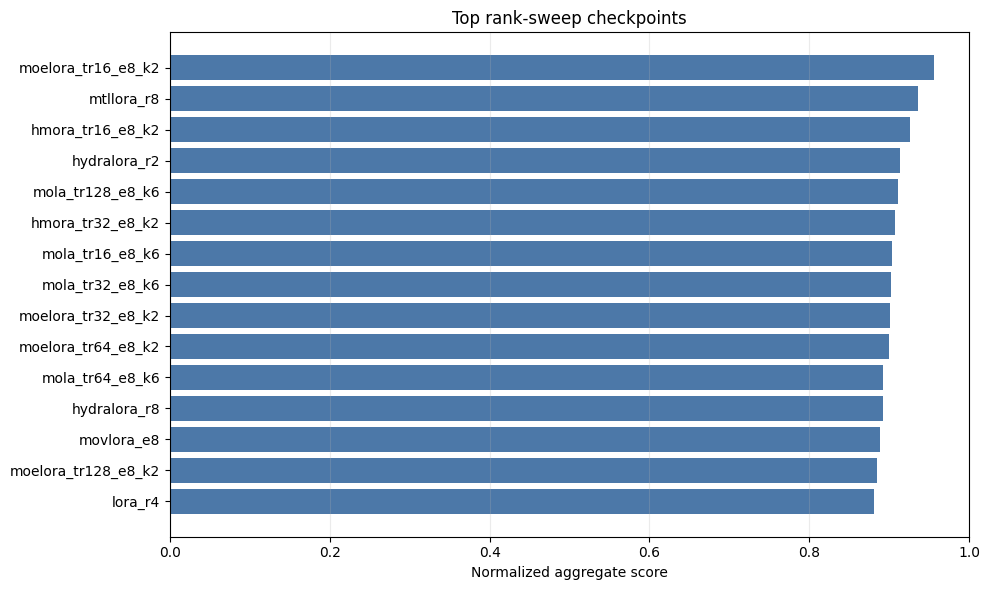

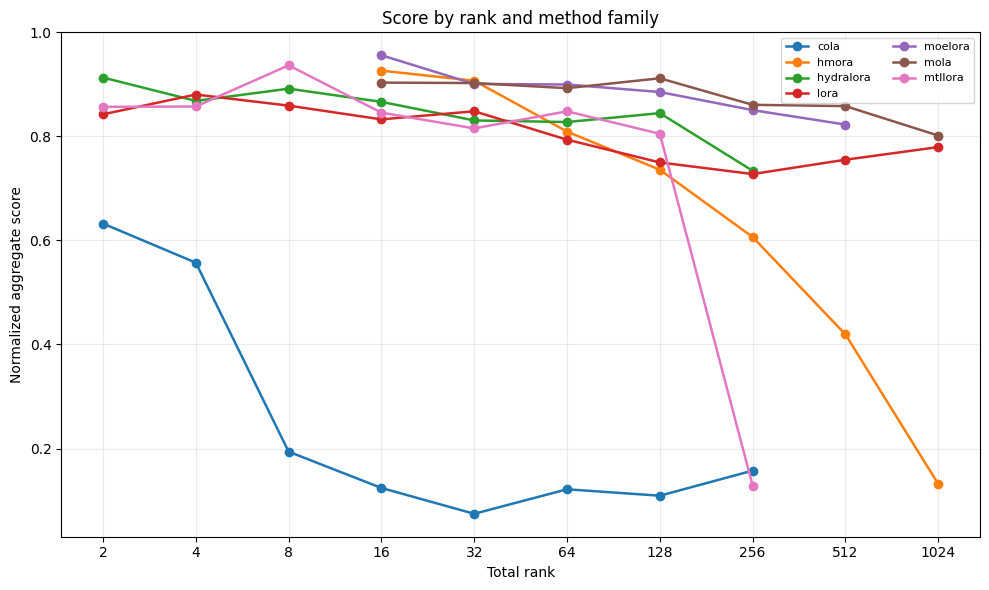

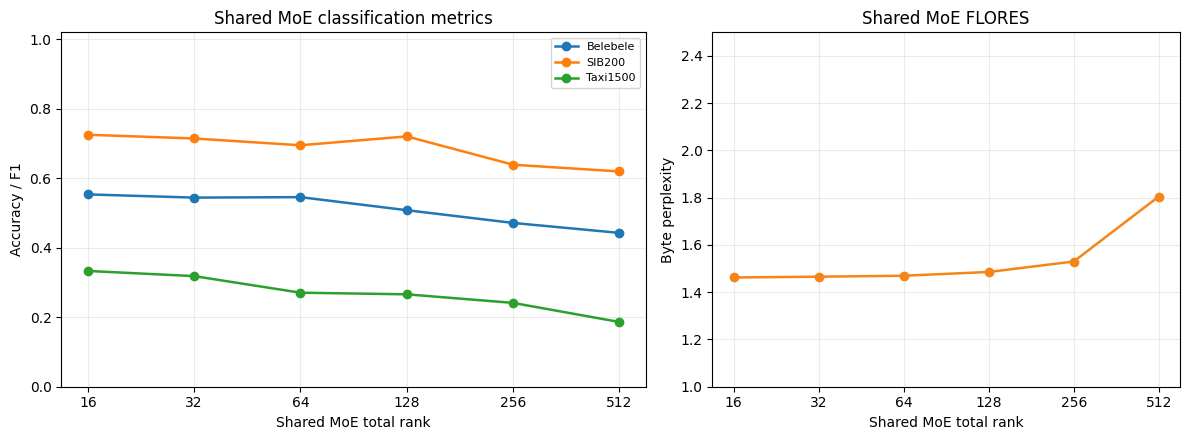

In [87]:
import os

plot_dir = ROOT / "outputs/pipeline_runs/moe_study_rank_expert_sweep_noctua2_a100_4gpu_10_langs_alltargets_calibrated/analysis/rank_selection/plots"
plot_dir.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("XDG_CACHE_HOME", str(plot_dir.parent / ".cache"))
os.environ.setdefault("MPLCONFIGDIR", str(plot_dir.parent / ".mplconfig"))

import matplotlib.pyplot as plt

rank_ticks = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
def plain_rank_ticks(ax, values=None):
    present = sorted({int(v) for v in (values if values is not None else rank_ticks) if pd.notna(v)})
    ticks = [tick for tick in rank_ticks if tick in present] or rank_ticks
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(tick) for tick in ticks])

top = run_scores.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.run_id, top.aggregate_score, color="#4C78A8")
ax.set(xlabel="Normalized aggregate score", title="Top rank-sweep checkpoints", xlim=(0, 1))
ax.grid(axis="x", alpha=0.25)
fig.tight_layout(); fig.savefig(plot_dir / "top_runs.png", dpi=180); plt.show()

ranked = run_scores[run_scores.total_rank.notna()]
fig, ax = plt.subplots(figsize=(10, 6))
for kind, group in ranked.groupby("kind"):
    group = group.sort_values("total_rank")
    ax.plot(group.total_rank, group.aggregate_score, marker="o", linewidth=1.8, label=kind)
ax.set_xscale("log", base=2)
plain_rank_ticks(ax, ranked.total_rank)
ax.set(xlabel="Total rank", ylabel="Normalized aggregate score", title="Score by rank and method family")
ax.grid(alpha=0.25); ax.legend(ncol=2, fontsize=8)
fig.tight_layout(); fig.savefig(plot_dir / "score_by_kind_rank.png", dpi=180); plt.show()

trend_exact = exact_moe_rank_summary.sort_values("total_rank")
fig, (ax_cls, ax_flores) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.25, 1]})
for column in ["Belebele", "SIB200", "Taxi1500"]:
    ax_cls.plot(trend_exact.total_rank, trend_exact[column], marker="o", linewidth=1.8, label=column)
ax_cls.set_xscale("log", base=2); plain_rank_ticks(ax_cls, trend_exact.total_rank)
ax_cls.set(title="Shared MoE classification metrics", xlabel="Shared MoE total rank", ylabel="Accuracy / F1", ylim=(0, 1.02))
ax_cls.grid(alpha=0.25); ax_cls.legend(fontsize=8)

flores = trend_exact["FLORES"]
ax_flores.plot(trend_exact.total_rank, flores.clip(upper=2.5), marker="o", linewidth=1.8, color="#F58518")
capped = flores.gt(2.5)
if capped.any():
    ax_flores.scatter(trend_exact.loc[capped, "total_rank"], [2.5] * capped.sum(), marker="^", s=70, color="#D62728", label=">2.5")
ax_flores.set_xscale("log", base=2); plain_rank_ticks(ax_flores, trend_exact.total_rank)
ax_flores.set(title="Shared MoE FLORES", xlabel="Shared MoE total rank", ylabel="Byte perplexity", ylim=(1.0, 2.5))
ax_flores.grid(alpha=0.25)
if capped.any():
    ax_flores.legend(fontsize=8)
fig.tight_layout(); fig.savefig(plot_dir / "shared_moe_rank_trend.png", dpi=180); plt.show()



## Dense rank views

Dense benchmark-family rank curves plus paired curve/heatmap panels for faster comparison. The heatmaps use rows as method families and columns as total rank.


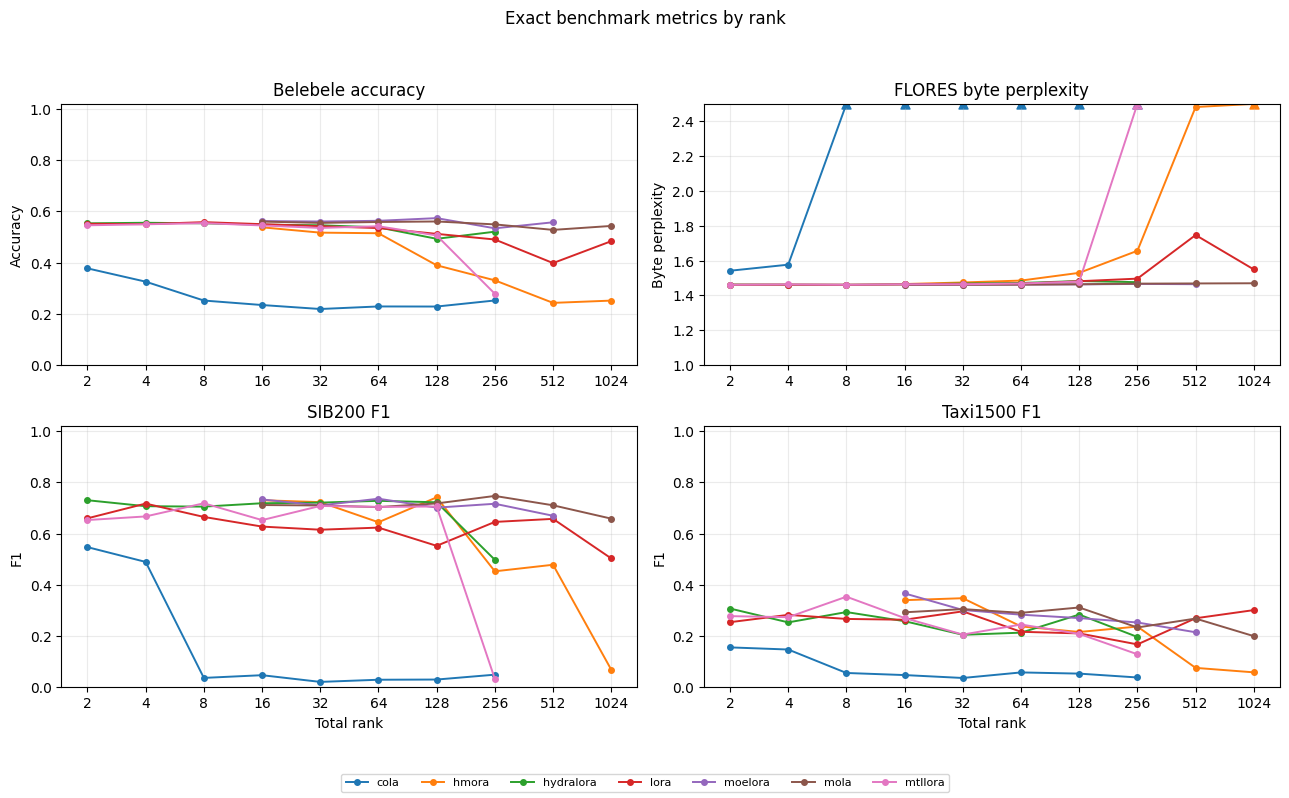

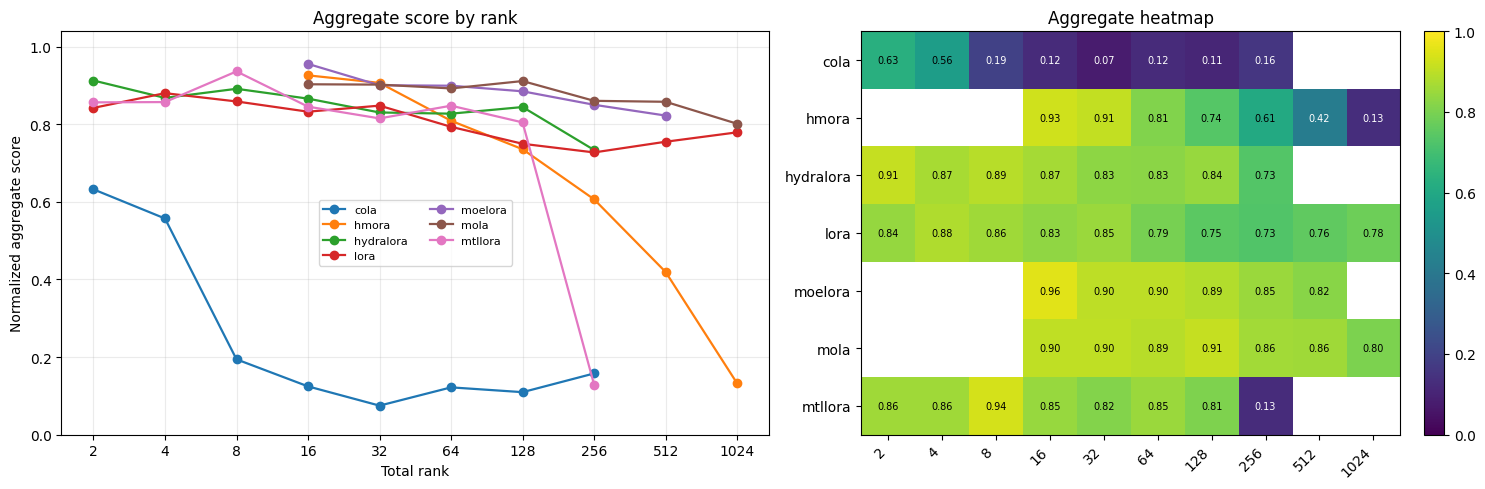

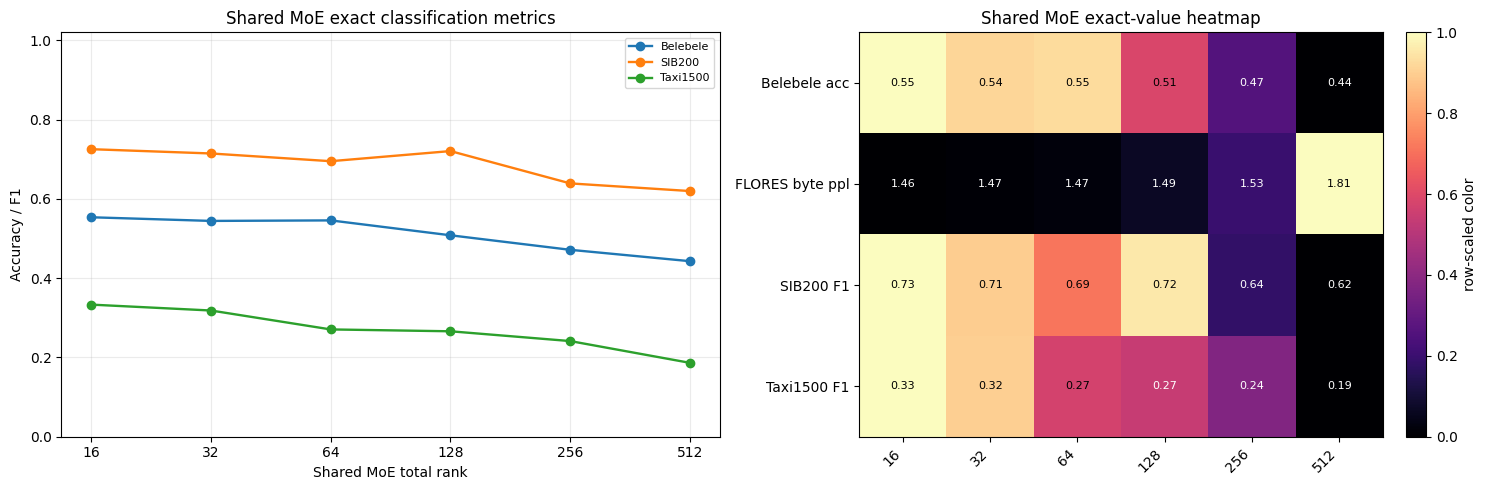

In [88]:
import os

plot_dir = ROOT / "outputs/pipeline_runs/moe_study_rank_expert_sweep_noctua2_a100_4gpu_10_langs_alltargets_calibrated/analysis/rank_selection/plots"
plot_dir.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("XDG_CACHE_HOME", str(plot_dir.parent / ".cache"))
os.environ.setdefault("MPLCONFIGDIR", str(plot_dir.parent / ".mplconfig"))

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

rank_ticks = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
def plain_rank_ticks(ax, values=None):
    present = sorted({int(v) for v in (values if values is not None else rank_ticks) if pd.notna(v)})
    ticks = [tick for tick in rank_ticks if tick in present] or rank_ticks
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(tick) for tick in ticks])

def rank_heatmap(ax, frame, value_col, title, cmap="viridis"):
    pivot = (
        frame[frame.total_rank.notna()]
        .assign(total_rank=lambda df: df.total_rank.astype(int).astype(str))
        .pivot_table(index="kind", columns="total_rank", values=value_col, aggfunc="mean")
    )
    rank_order = [str(r) for r in rank_ticks if str(r) in pivot.columns]
    pivot = pivot.reindex(columns=rank_order).sort_index()
    image = ax.imshow(pivot.fillna(float("nan")), aspect="auto", cmap=cmap, norm=Normalize(0, 1))
    ax.set_title(title)
    ax.set_xticks(range(len(pivot.columns)), pivot.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(pivot.index)), pivot.index)
    for y, kind in enumerate(pivot.index):
        for x, rank in enumerate(pivot.columns):
            value = pivot.loc[kind, rank]
            if pd.notna(value):
                ax.text(x, y, f"{value:.2f}", ha="center", va="center", fontsize=7, color="white" if value < 0.55 else "black")
    return image

def exact_benchmark_axis(ax, frame, benchmark):
    for kind, group in frame.groupby("kind"):
        group = group.sort_values("total_rank")
        if benchmark == "FLORES":
            y = group[benchmark].clip(upper=2.5)
            line = ax.plot(group.total_rank, y, marker="o", linewidth=1.4, markersize=4, label=kind)[0]
            capped = group[benchmark].gt(2.5)
            if capped.any():
                ax.scatter(group.loc[capped, "total_rank"], [2.5] * capped.sum(), marker="^", s=42, color=line.get_color())
        else:
            ax.plot(group.total_rank, group[benchmark], marker="o", linewidth=1.4, markersize=4, label=kind)
    ax.set_xscale("log", base=2); plain_rank_ticks(ax, frame.total_rank)
    ax.grid(alpha=0.25)
    if benchmark == "FLORES":
        ax.set(title="FLORES byte perplexity", ylabel="Byte perplexity", ylim=(1.0, 2.5))
    elif benchmark == "Belebele":
        ax.set(title="Belebele accuracy", ylabel="Accuracy", ylim=(0, 1.02))
    else:
        ax.set(title=f"{benchmark} F1", ylabel="F1", ylim=(0, 1.02))

# Exact benchmark metrics by rank and approach. FLORES values above 2.5 are shown at the cap with triangle markers.
ranked_exact = exact_scores[exact_scores.total_rank.notna()].copy()
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=False)
for ax, benchmark in zip(axes.flat, benchmarks):
    exact_benchmark_axis(ax, ranked_exact, benchmark)
for ax in axes[-1]:
    ax.set_xlabel("Total rank")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=7, fontsize=8)
fig.suptitle("Exact benchmark metrics by rank", y=0.98)
fig.tight_layout(rect=(0, 0.06, 1, 0.95))
fig.savefig(plot_dir / "dense_benchmark_family_rank_curves.png", dpi=180)
plt.show()

# Existing aggregate curve beside its normalized aggregate heatmap.
ranked = run_scores[run_scores.total_rank.notna()].copy()
fig, (ax_curve, ax_heat) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.2, 1]})
for kind, group in ranked.groupby("kind"):
    group = group.sort_values("total_rank")
    ax_curve.plot(group.total_rank, group.aggregate_score, marker="o", linewidth=1.6, label=kind)
ax_curve.set_xscale("log", base=2); plain_rank_ticks(ax_curve, ranked.total_rank)
ax_curve.set(title="Aggregate score by rank", xlabel="Total rank", ylabel="Normalized aggregate score", ylim=(0, 1.04))
ax_curve.grid(alpha=0.25); ax_curve.legend(ncol=2, fontsize=8)
image = rank_heatmap(ax_heat, ranked, "aggregate_score", "Aggregate heatmap")
fig.colorbar(image, ax=ax_heat, fraction=0.046, pad=0.04)
fig.tight_layout(); fig.savefig(plot_dir / "dense_aggregate_curve_heatmap.png", dpi=180); plt.show()

# Shared-MoE exact metrics beside an exact-value heatmap. Heatmap color is row-normalized because metrics use different scales.
trend_exact = exact_moe_rank_summary.sort_values("total_rank")
fig, (ax_curve, ax_heat) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.15, 1]})
for column in ["Belebele", "SIB200", "Taxi1500"]:
    ax_curve.plot(trend_exact.total_rank, trend_exact[column], marker="o", linewidth=1.7, label=column)
ax_curve.set_xscale("log", base=2); plain_rank_ticks(ax_curve, trend_exact.total_rank)
ax_curve.set(title="Shared MoE exact classification metrics", xlabel="Shared MoE total rank", ylabel="Accuracy / F1", ylim=(0, 1.02))
ax_curve.grid(alpha=0.25); ax_curve.legend(fontsize=8)

moe_heat = trend_exact.set_index(trend_exact.total_rank.astype(int).astype(str))[benchmarks].T
moe_heat_plot = moe_heat.copy()
moe_heat_plot.loc["FLORES"] = moe_heat_plot.loc["FLORES"].clip(upper=2.5)
row_scaled = moe_heat_plot.sub(moe_heat_plot.min(axis=1), axis=0).div((moe_heat_plot.max(axis=1) - moe_heat_plot.min(axis=1)).replace(0, 1), axis=0)
image = ax_heat.imshow(row_scaled, aspect="auto", cmap="magma", norm=Normalize(0, 1))
ax_heat.set_title("Shared MoE exact-value heatmap")
ax_heat.set_xticks(range(len(moe_heat.columns)), moe_heat.columns, rotation=45, ha="right")
ax_heat.set_yticks(range(len(moe_heat.index)), ["Belebele acc", "FLORES byte ppl", "SIB200 F1", "Taxi1500 F1"])
for y, row in enumerate(moe_heat.index):
    for x, col in enumerate(moe_heat.columns):
        value = moe_heat.loc[row, col]
        label = ">2.5" if row == "FLORES" and value > 2.5 else f"{value:.2f}"
        ax_heat.text(x, y, label, ha="center", va="center", fontsize=8, color="white" if row_scaled.loc[row, col] < 0.55 else "black")
fig.colorbar(image, ax=ax_heat, fraction=0.046, pad=0.04, label="row-scaled color")
fig.tight_layout(); fig.savefig(plot_dir / "dense_shared_moe_curve_heatmap.png", dpi=180); plt.show()



## Why this makes sense

We increase the number of trainable parameters, but the data and time budget stay exactly the same.

This is a problem because higher capacity means more weights need to be updated. With a fixed 3.6h time budget, larger-rank runs also take longer per step, so they complete fewer training steps overall.

So for rank 256+, we get:

more trainable parameters → slower steps → fewer total updates → less training signal per parameter

In short: we add capacity, but do not give the model enough extra data or compute to use it effectively. But this was intended. We knew this before we computed the runs

## Expert-count selection

Combined expert/head sweep analysis over the observed benchmark roots. The aggregate score uses the same normalized benchmark-family scoring as the rank analysis; efficiency is reported as the smallest count within 98% of the best mean score.


In [ ]:
# Expert/head benchmark aggregation from combined result roots.
import importlib
import sys
sys.path.insert(0, str(ROOT))

import scripts.analysis.expert_sweep_select_best_expert as expert_select
import scripts.analysis.rank_sweep_select_best_rank as rank_select

expert_select = importlib.reload(expert_select)
rank_select = importlib.reload(rank_select)

EXPERT_ROOTS = expert_select.DEFAULT_ROOTS
collect_expert_results = expert_select._collect
efficient_choice = expert_select._efficient_choice
summarize_exact_expert_group = expert_select._summarize_exact_group
summarize_exact_expert_runs = expert_select._summarize_exact_runs
summarize_expert_group = expert_select._summarize_group
summarize_expert_runs = expert_select._summarize_runs
normalize_rank_scores = rank_select._normalized_scores

expert_roots = [ROOT / root for root in EXPERT_ROOTS]
expert_run_rows, expert_raw_rows = collect_expert_results(expert_roots)
expert_metrics = pd.DataFrame(normalize_rank_scores(expert_raw_rows))
expert_run_scores = pd.DataFrame(summarize_expert_runs(expert_run_rows, expert_metrics.to_dict("records")))
expert_exact_scores = pd.DataFrame(summarize_exact_expert_runs(expert_run_rows, expert_raw_rows))
expert_scored = expert_run_scores[expert_run_scores.aggregate_score.notna()].copy()

expert_count_summary = pd.DataFrame(summarize_expert_group(expert_scored.to_dict("records"), ["expert_count"]))
routed_moe_count_summary = pd.DataFrame(
    summarize_expert_group(
        expert_scored[expert_scored.kind.isin(["mola", "movlora", "hmora"])].to_dict("records"),
        ["expert_count"],
    )
)
kind_expert_summary = pd.DataFrame(summarize_expert_group(expert_scored.to_dict("records"), ["kind", "expert_count"]))
kind_exact_summary = pd.DataFrame(summarize_exact_expert_group(expert_exact_scores.to_dict("records"), ["kind", "expert_count"]))
large_topk_summary = pd.DataFrame(
    summarize_expert_group(
        expert_scored[expert_scored.top_k.notna() & expert_scored.expert_count.isin([8, 16, 32])].to_dict("records"),
        ["kind", "expert_count", "top_k"],
    )
)
large_topk_exact_summary = pd.DataFrame(
    summarize_exact_expert_group(
        expert_exact_scores[expert_exact_scores.top_k.notna() & expert_exact_scores.expert_count.isin([8, 16, 32])].to_dict("records"),
        ["kind", "expert_count", "top_k"],
    )
)

display(expert_run_scores.head(15))
display(expert_count_summary)
display(routed_moe_count_summary)
display(large_topk_summary)



In [ ]:
expert_plot_dir = ROOT / "outputs/pipeline_runs/moe_study_expert_head_sweep_r2_noctua2_a100_4gpu_10_langs_ready/analysis/expert_selection/plots"
expert_plot_dir.mkdir(parents=True, exist_ok=True)

counts = [2, 4, 8, 16, 32]
def expert_count_ticks(ax, values):
    ticks = [count for count in counts if count in set(int(v) for v in values if pd.notna(v))]
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(tick) for tick in ticks])

fig, ax = plt.subplots(figsize=(10, 6))
top = expert_run_scores.head(15).iloc[::-1]
ax.barh(top.run_id, top.aggregate_score, color="#4C78A8")
ax.set(xlabel="Normalized aggregate score", title="Top expert/head sweep checkpoints", xlim=(0, 1))
ax.grid(axis="x", alpha=0.25)
fig.tight_layout(); fig.savefig(expert_plot_dir / "expert_top_runs.png", dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
for kind, group in kind_expert_summary.groupby("kind"):
    group = group.sort_values("expert_count")
    ax.plot(group.expert_count, group.mean_aggregate_score, marker="o", linewidth=1.7, label=kind)
ax.set_xscale("log", base=2); expert_count_ticks(ax, expert_scored.expert_count)
ax.set(xlabel="Expert/head count", ylabel="Mean normalized aggregate score", title="Mean score by count and method family", ylim=(0, 1.04))
ax.grid(alpha=0.25); ax.legend(ncol=2, fontsize=8)
fig.tight_layout(); fig.savefig(expert_plot_dir / "expert_score_by_kind_count.png", dpi=180); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=False)
exact_specs = [
    ("Belebele", "mean_belebele_acc", "Accuracy", (0, 1.02)),
    ("FLORES", "mean_flores_byte_perplexity", "Byte perplexity", (1.0, 2.5)),
    ("SIB200", "mean_sib200_f1", "F1", (0, 1.02)),
    ("Taxi1500", "mean_taxi1500_f1", "F1", (0, 1.02)),
]
for ax, (label, field, ylabel, ylim) in zip(axes.flat, exact_specs):
    for kind, group in kind_exact_summary[kind_exact_summary.expert_count.notna()].groupby("kind"):
        group = group.sort_values("expert_count")
        y = group[field].clip(upper=2.5) if label == "FLORES" else group[field]
        line = ax.plot(group.expert_count, y, marker="o", linewidth=1.2, markersize=4, label=kind)[0]
        if label == "FLORES":
            capped = group[field].gt(2.5)
            if capped.any():
                ax.scatter(group.loc[capped, "expert_count"], [2.5] * capped.sum(), marker="^", s=38, color=line.get_color())
    ax.set_xscale("log", base=2); expert_count_ticks(ax, kind_exact_summary.expert_count)
    ax.set(title=f"{label} by count", xlabel="Expert/head count", ylabel=ylabel, ylim=ylim)
    ax.grid(alpha=0.25)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=7, fontsize=8)
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(expert_plot_dir / "expert_exact_benchmark_family_by_count.png", dpi=180); plt.show()

fig, (ax_curve, ax_heat) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.1, 1]})
summary = expert_count_summary.sort_values("expert_count")
ax_curve.plot(summary.expert_count, summary.mean_aggregate_score, marker="o", label="mean score")
ax_curve.plot(summary.expert_count, summary.best_aggregate_score, marker="o", label="best run")
ax_curve.set_xscale("log", base=2); expert_count_ticks(ax_curve, summary.expert_count)
ax_curve.set(xlabel="Expert/head count", ylabel="Normalized aggregate score", title="Overall expert-count trend", ylim=(0, 1.04))
ax_curve.grid(alpha=0.25); ax_curve.legend(fontsize=8)

heat = kind_expert_summary.pivot_table(index="kind", columns="expert_count", values="mean_aggregate_score").reindex(columns=counts)
image = ax_heat.imshow(heat, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax_heat.set_title("Mean score heatmap")
ax_heat.set_xticks(range(len(heat.columns)), [str(int(c)) for c in heat.columns])
ax_heat.set_yticks(range(len(heat.index)), heat.index)
for y, kind in enumerate(heat.index):
    for x, count in enumerate(heat.columns):
        value = heat.loc[kind, count]
        if pd.notna(value):
            ax_heat.text(x, y, f"{value:.2f}", ha="center", va="center", fontsize=7, color="white" if value < 0.55 else "black")
fig.colorbar(image, ax=ax_heat, fraction=0.046, pad=0.04)
fig.tight_layout(); fig.savefig(expert_plot_dir / "expert_count_curve_heatmap.png", dpi=180); plt.show()



In [ ]:
# Dense top-k views for larger expert counts: 8, 16, 32.
large = large_topk_summary.copy()
large["row"] = large.kind + "_e" + large.expert_count.astype(int).astype(str)
row_order = sorted(large.row.unique(), key=lambda value: (int(value.rsplit("_e", 1)[1]), value))
topk_cols = [1, 2, 4, 8, 16]

fig, ax = plt.subplots(figsize=(9, max(4, 0.38 * len(row_order))))
heat = large.pivot_table(index="row", columns="top_k", values="mean_aggregate_score").reindex(index=row_order, columns=topk_cols)
image = ax.imshow(heat, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_title("Large-count top-k effect: aggregate score")
ax.set_xlabel("top-k")
ax.set_xticks(range(len(heat.columns)), [str(int(c)) for c in heat.columns])
ax.set_yticks(range(len(heat.index)), heat.index)
for y, row in enumerate(heat.index):
    for x, col in enumerate(heat.columns):
        value = heat.loc[row, col]
        if pd.notna(value):
            ax.text(x, y, f"{value:.2f}", ha="center", va="center", fontsize=7, color="white" if value < 0.55 else "black")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout(); fig.savefig(expert_plot_dir / "expert_topk_large_counts_aggregate_heatmap.png", dpi=180); plt.show()

large_exact = large_topk_exact_summary.copy()
large_exact["row"] = large_exact.kind + "_e" + large_exact.expert_count.astype(int).astype(str)
fig, axes = plt.subplots(2, 2, figsize=(13, max(7, 0.42 * len(row_order))))
exact_heat_specs = [
    ("Belebele acc", "mean_belebele_acc", False),
    ("FLORES byte ppl", "mean_flores_byte_perplexity", True),
    ("SIB200 F1", "mean_sib200_f1", False),
    ("Taxi1500 F1", "mean_taxi1500_f1", False),
]
for ax, (title, field, cap_flores) in zip(axes.flat, exact_heat_specs):
    raw = large_exact.pivot_table(index="row", columns="top_k", values=field).reindex(index=row_order, columns=topk_cols)
    display_values = raw.clip(upper=2.5) if cap_flores else raw
    row_min = display_values.min(axis=1)
    row_span = (display_values.max(axis=1) - row_min).replace(0, 1)
    color_values = display_values.sub(row_min, axis=0).div(row_span, axis=0)
    image = ax.imshow(color_values, aspect="auto", cmap="magma", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xlabel("top-k")
    ax.set_xticks(range(len(raw.columns)), [str(int(c)) for c in raw.columns])
    ax.set_yticks(range(len(raw.index)), raw.index)
    for y, row in enumerate(raw.index):
        for x, col in enumerate(raw.columns):
            value = raw.loc[row, col]
            if pd.notna(value):
                text = ">2.5" if cap_flores and value > 2.5 else f"{value:.2f}"
                color = "white" if color_values.loc[row, col] < 0.55 else "black"
                ax.text(x, y, text, ha="center", va="center", fontsize=7, color=color)
fig.tight_layout(); fig.savefig(expert_plot_dir / "expert_topk_large_counts_benchmark_heatmaps.png", dpi=180); plt.show()

